In [5]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

pd.set_option("display.precision", 2)

## Load the data

Two sheets matter: `ff_factors` (columns `mktrf`, `rf`, `smb`, `hml`) and `ff_portfolios25` (the 25 portfolios, named `sXbY_vwret`: X = size quintile, 1 = small; Y = book-to-market quintile, 1 = low).

Returns are stored as **decimals** (0.0546 = 5.46%), monthly, from Jan 1932 to Aug 2018.

The last two `date` cells in the portfolios sheet are blank, so we line the two sheets up by `year` and `month` instead of by `date`.

In [6]:
DATA_PATH = "/Users/jballesteros/Documents/git/uchicago-mpp/4_autumn_2026/investments/pset_4/ps4_FFData-1.xlsx"

factors = pd.read_excel(DATA_PATH, sheet_name="ff_factors")
ports   = pd.read_excel(DATA_PATH, sheet_name="ff_portfolios25")

# Index both sheets by month, so rows can only pair up with the same month
for df in (factors, ports):
    df.index = pd.PeriodIndex.from_fields(year=df["year"], month=df["month"], freq="M")

assert factors.index.equals(ports.index), "The two sheets don't cover the same months"

port_cols = [c for c in ports.columns if c.endswith("_vwret")]
print(f"{len(factors)} months: {factors.index[0]} to {factors.index[-1]}")
print(f"{len(port_cols)} portfolios: {port_cols[0]} ... {port_cols[-1]}")

1040 months: 1932-01 to 2018-08
25 portfolios: s1b1_vwret ... s5b5_vwret


## Excess returns

The CAPM regression is about returns **in excess of the risk-free rate** (Lecture 3 Part 2, slide 15). The risk-free rate changes over time, so each portfolio's return is matched with **that month's** `rf`.

`.sub(..., axis=0)` subtracts `rf` row by row, the same as the `$E2` formula in Excel.

`mktrf` is **already** an excess return, so it stays as is.

In [7]:
excess = ports[port_cols].sub(factors["rf"], axis=0)
excess.columns = [c.replace("_vwret", "") for c in excess.columns]   # s1b1, s1b2, ...

mktrf = factors["mktrf"]
excess.head(3)

,s1b1,s1b2,s1b3,s1b4,s1b5,s2b1,s2b2,s2b3,s2b4,s2b5,...,s4b1,s4b2,s4b3,s4b4,s4b5,s5b1,s5b2,s5b3,s5b4,s5b5
1932-01,0.05,-6.22e-02,0.08,0.15,0.06,-5.34e-03,-0.02,0.05,0.14,0.18,...,-0.04,-6.26e-03,-7.88e-03,0.04,0.02,-0.04,-0.02,0.03,0.11,0.08
1932-02,-0.13,-2.45e-03,0.06,-0.03,0.03,-5.64e-02,0.03,-0.03,-0.05,-0.01,...,0.03,4.98e-02,-1.63e-02,0.01,0.04,0.07,0.05,0.03,-0.04,0.14
1932-03,-0.23,-4.07e-02,-0.03,-0.10,-0.13,-5.05e-02,-0.14,-0.12,-0.04,-0.13,...,-0.11,-1.11e-01,-1.15e-01,-0.13,-0.10,-0.11,-0.10,-0.14,-0.23,0.02


## Helper: lay out 25 numbers as a Fama-French table

Every table in this problem set has 5 rows for size (Small to Big) and 5 columns for book-to-market (Low to High). Portfolio `sXbY` goes in row X, column Y.

Remember that low B/M means **growth** and high B/M means **value** (Lecture 4 Part 2, slide 9).

In [8]:
ROWS = ["Small", "2", "3", "4", "Big"]
COLS = ["Low", "2", "3", "4", "High"]

def to_grid(series):
    # Turn a Series indexed by 's1b1'...'s5b5' into a 5x5 size x B/M table
    grid = pd.DataFrame(index=ROWS, columns=COLS, dtype=float)
    for name, value in series.items():
        size, bm = int(name[1]), int(name[3])
        grid.iloc[size - 1, bm - 1] = value
    grid.index.name, grid.columns.name = "Size", "Book-Market"
    return grid

## 1(a): CAPM alphas and betas

For each portfolio *i*, run the time-series regression

$$r_{i,t} - r_{f,t} = \alpha_i + \beta_i (r_{m,t} - r_{f,t}) + \epsilon_{i,t}$$

The slope is beta, which equals cov/var (Lecture 3 Part 2, slide 15). The intercept is alpha: the average excess return that beta does **not** explain (slide 18).

`sm.add_constant` adds the column of 1s that gives the regression an intercept. Without it, you'd be forcing alpha = 0.

Alpha comes out monthly, in decimals, so it gets multiplied by 12 × 100 to annualize it and express it in percent. Beta has no units, so it stays as is.

The t-stat on alpha is a bonus Excel's `SLOPE`/`INTERCEPT` doesn't give you. It tells you whether an alpha is **statistically** different from zero. Roughly, |t| > 2 means significant at the 5% level.

In [9]:
X = sm.add_constant(mktrf)          # columns: const, mktrf

capm = {}
for p in excess.columns:
    fit = sm.OLS(excess[p], X).fit()
    capm[p] = {
        "alpha_monthly": fit.params["const"],
        "beta":          fit.params["mktrf"],
        "alpha_t":       fit.tvalues["const"],
    }
capm = pd.DataFrame(capm).T
capm["alpha_annual_pct"] = capm["alpha_monthly"] * 12 * 100

**Check:** the problem set gives `s2b1` a beta of 1.31 and an alpha of −1.98. If these match, the setup is right.

In [10]:
print(f"s2b1 beta  = {capm.loc['s2b1', 'beta']:.2f}   (expected 1.31)")
print(f"s2b1 alpha = {capm.loc['s2b1', 'alpha_annual_pct']:.2f}  (expected -1.98)")

s2b1 beta  = 1.31   (expected 1.31)
s2b1 alpha = -1.98  (expected -1.98)


**Table 1: Estimated CAPM β's**

In [11]:
table1 = to_grid(capm["beta"])
table1

Book-Market,Low,2,3,4,High
Size,,,,,
Small,1.65,1.44,1.40,1.27,1.39
2,1.31,1.26,1.23,1.24,1.39
3,1.28,1.13,1.15,1.18,1.38
4,1.09,1.09,1.13,1.16,1.43
Big,0.95,0.94,0.96,1.11,1.28


**Table 2: Estimated CAPM α's (annualized, %)**

In [12]:
table2 = to_grid(capm["alpha_annual_pct"])
table2

Book-Market,Low,2,3,4,High
Size,,,,,
Small,-4.88,-1.62,1.92,5.14,5.91
2,-1.98,1.71,2.58,3.89,4.18
3,-1.17,2.20,2.12,3.45,3.12
4,0.07,0.68,1.86,2.90,1.17
Big,-0.16,-0.11,1.39,-0.52,1.58


**Optional: t-statistics on the CAPM α's**

In [13]:
to_grid(capm["alpha_t"])

Book-Market,Low,2,3,4,High
Size,,,,,
Small,-1.55,-0.71,1.04,2.87,2.78
2,-1.26,1.29,2.07,2.88,2.43
3,-0.99,2.51,2.33,3.09,1.97
4,0.08,0.99,2.13,2.78,0.74
Big,-0.28,-0.19,1.73,-0.48,0.94


### 1(a) write-up: patterns and how the CAPM does

*[Your write-up here. Describe beta by size and by B/M, alpha by size and by B/M, then what that means for the CAPM.]*

## 1(b): Average excess returns

The sample average of each portfolio's monthly excess return, annualized (× 12) and in percent (× 100).

In [14]:
avg_excess = excess.mean() * 12 * 100
table1b = to_grid(avg_excess)
table1b

Book-Market,Low,2,3,4,High
Size,,,,,
Small,9.75,11.21,14.32,16.44,18.29
2,9.63,12.93,13.49,14.88,16.57
3,10.22,12.24,12.32,13.92,15.42
4,9.76,10.37,11.93,13.18,13.88
Big,8.26,8.29,9.93,9.36,12.91


**Consistency check.** Averaging both sides of the regression gives: average excess return = α + β × average market excess return (Lecture 3 Part 2, slide 18).

So (average − α) / β should give the **same** implied market premium for every portfolio, and it should equal the average of `mktrf`.

In [15]:
mkt_prem = mktrf.mean() * 12 * 100
implied = (avg_excess - capm["alpha_annual_pct"]) / capm["beta"]

print(f"Average mktrf (annual %):           {mkt_prem:.4f}")
print(f"Implied by the 25 portfolios:       min {implied.min():.4f}, max {implied.max():.4f}")

Average mktrf (annual %):           8.8876
Implied by the 25 portfolios:       min 8.8876, max 8.8876


## 1(c): CAPM predicted excess returns

Imposing α = 0, the CAPM predicts

$$E[r_i - r_f] = \beta_i \times \overline{(r_m - r_f)}$$

This is the Security Market Line (Lecture 3 Part 2, slides 12–13). `mkt_prem` is already annualized and in percent, and beta has no units, so the product is already annual percent. **Don't multiply by 12 × 100 again.**

In [16]:
capm_pred = capm["beta"] * mkt_prem
table1c = to_grid(capm_pred)
table1c

Book-Market,Low,2,3,4,High
Size,,,,,
Small,14.63,12.83,12.40,11.30,12.38
2,11.61,11.22,10.91,10.99,12.40
3,11.39,10.04,10.20,10.46,12.31
4,9.69,9.69,10.08,10.28,12.71
Big,8.42,8.40,8.54,9.88,11.33


**Check:** actual − predicted should equal each portfolio's alpha from Table 2.

In [17]:
gap = (avg_excess - capm_pred) - capm["alpha_annual_pct"]
print(f"Largest mismatch: {gap.abs().max():.2e}  (should be ~0)")

Largest mismatch: 1.47e-14  (should be ~0)


### Plot: predicted vs. actual

Each dot is one portfolio, plotted at (CAPM prediction, actual average). If the CAPM held, every dot would sit on the **45° line**. A dot's vertical distance from the line is its alpha.

Both axes use the same limits and the plot is square, so the 45° line really is at 45°. The limits are stored in `LIMS`, so you can reuse them in Question 2 and the two figures will be directly comparable.

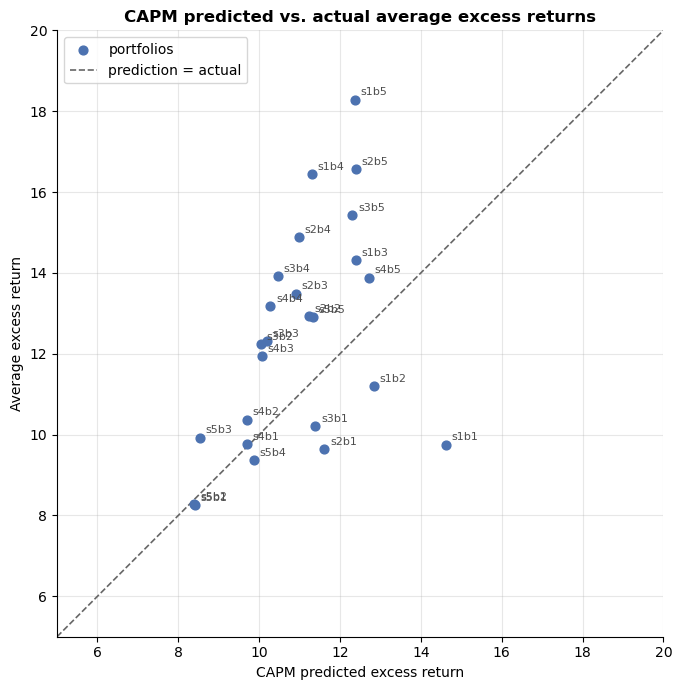

In [ ]:
def plot_pred_vs_actual(pred, actual, title, xlabel, lims):
    fig, ax = plt.subplots(figsize=(7,7))
    ax.scatter(pred, actual, s=40, color="#4C72B0", zorder=3, label="portfolios")
    for name in pred.index:
        ax.annotate(name, (pred[name], actual[name]), xytext=(4, 3),
                    textcoords="offset points", fontsize=8, color="0.3")
    ax.plot(lims, lims, color="0.4", linestyle="--", linewidth=1.2,
            label="prediction = actual")
    ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Average excess return")
    ax.set_title(title, fontweight="bold")
    ax.legend(loc="upper left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    return fig, ax

LIMS = (5, 20)   # same limits on both axes; widen if any point falls outside

plot_pred_vs_actual(capm_pred, avg_excess,
                    "CAPM predicted vs. actual average excess returns",
                    "CAPM predicted excess return", LIMS)
plt.show()

### 1(c) write-up: what patterns do you see?

*[Your write-up here. Compare the left-to-right and bottom-to-top spreads, note which portfolios sit above and below the line, and identify the outlier.]*

## Optional: export tables for Quarto

`to_markdown()` prints a table as Markdown that you can paste into your `.qmd`. If you render this notebook with Quarto directly, you don't need this.

In [19]:
print(table1.round(2).to_markdown())

| Size   |   Low |    2 |    3 |    4 |   High |
|:-------|------:|-----:|-----:|-----:|-------:|
| Small  |  1.65 | 1.44 | 1.4  | 1.27 |   1.39 |
| 2      |  1.31 | 1.26 | 1.23 | 1.24 |   1.39 |
| 3      |  1.28 | 1.13 | 1.15 | 1.18 |   1.38 |
| 4      |  1.09 | 1.09 | 1.13 | 1.16 |   1.43 |
| Big    |  0.95 | 0.94 | 0.96 | 1.11 |   1.28 |


---
# Question 2: Fama-French three-factor model

*Repeat parts (a) and (c) with the three-factor model:*

$$r_{i,t} - r_{f,t} = \alpha_i + \beta_i^{m} f_{m,t} + \beta_i^{smb} f_{smb,t} + \beta_i^{hml} f_{hml,t} + \epsilon_{i,t}$$

*Fill in Tables 3–6, compute the three-factor predicted excess returns, plot them against the actual averages from 1(b), and compare the figure to the one from Question 1.*

In [22]:
factors

,date,year,month,mktrf,rf,smb,hml
1932-01,19320130,1932,1,-1.58e-02,2.30e-03,0.04,9.04e-02
1932-02,19320229,1932,2,5.46e-02,2.30e-03,-0.03,-1.45e-02
1932-03,19320331,1932,3,-1.12e-01,1.60e-03,0.02,-2.32e-02
1932-04,19320430,1932,4,-1.80e-01,1.10e-03,0.01,1.42e-02
1932-05,19320531,1932,5,-2.05e-01,6.00e-04,0.04,-3.28e-02
...,...,...,...,...,...,...,...
2018-04,20180430,2018,4,2.90e-03,1.40e-03,0.01,5.30e-03
2018-05,20180531,2018,5,2.65e-02,1.40e-03,0.05,-3.16e-02
2018-06,20180629,2018,6,4.80e-03,1.40e-03,0.01,-2.39e-02
2018-07,20180731,2018,7,3.19e-02,1.60e-03,-0.02,3.90e-03


In [24]:
mktrf = factors["mktrf"]
smb = factors["smb"]
hml = factors["hml"]

In [26]:
X3 = sm.add_constant(factors[["mktrf", "smb", "hml"]])

In [28]:
ff3 = {}
for p in excess.columns:
    fit = sm.OLS(excess[p], X3).fit()
    ff3[p] = {
        "alpha_monthly": fit.params["const"],
        "beta_mkt":      fit.params["mktrf"],
        "beta_smb":      fit.params["smb"],
        "beta_hml":      fit.params["hml"],
        "alpha_t":       fit.tvalues["const"],
    }
ff3 = pd.DataFrame(ff3).T
ff3["alpha_annual_pct"] = ff3["alpha_monthly"] * 12 * 100

In [29]:
table3 = to_grid(ff3["beta_mkt"])   # beta_mkt
table4 = to_grid(ff3["beta_smb"])
table5 = to_grid(ff3["beta_hml"])
table6 = to_grid(ff3["alpha_annual_pct"])

In [32]:
display(table3.round(2), table4.round(2), table5.round(2), table6.round(2))

Book-Market,Low,2,3,4,High
Size,,,,,
Small,1.25,1.08,1.06,0.92,0.97
2,1.10,1.03,0.99,0.98,1.07
3,1.14,1.01,1.01,0.99,1.12
4,1.07,1.03,1.04,1.03,1.22
Big,1.02,0.99,0.97,1.05,1.16


Book-Market,Low,2,3,4,High
Size,,,,,
Small,1.50,1.54,1.21,1.24,1.32
2,1.14,0.97,0.82,0.81,0.90
3,0.82,0.51,0.43,0.46,0.60
4,0.33,0.21,0.20,0.21,0.32
Big,-0.15,-0.20,-0.25,-0.18,-0.16


Book-Market,Low,2,3,4,High
Size,,,,,
Small,0.44,0.22,0.50,0.57,0.91
2,-0.24,0.14,0.37,0.57,0.89
3,-0.24,0.04,0.32,0.55,0.87
4,-0.35,0.09,0.35,0.56,0.94
Big,-0.26,0.03,0.33,0.64,0.98


Book-Market,Low,2,3,4,High
Size,,,,,
Small,-8.42,-4.40,-1.48,1.45,0.88
2,-2.56,-0.04,0.18,0.76,-0.22
3,-1.33,1.39,0.41,0.86,-0.84
4,0.93,0.06,0.32,0.58,-2.66
Big,0.98,0.06,0.51,-2.63,-1.78


In [37]:
prem = factors[["mktrf", "smb", "hml"]].mean() * 12 * 100
prem

mktrf    8.89
smb      3.21
hml      5.00
dtype: float64

In [38]:
ff3_pred = (ff3["beta_mkt"] * prem["mktrf"]
          + ff3["beta_smb"] * prem["smb"]
          + ff3["beta_hml"] * prem["hml"])

to_grid(ff3_pred).round(2)

Book-Market,Low,2,3,4,High
Size,,,,,
Small,18.17,15.60,15.80,14.99,17.40
2,12.19,12.97,13.30,14.12,16.80
3,11.55,10.85,11.92,13.06,16.26
4,8.82,10.31,11.62,12.60,16.54
Big,7.28,8.23,9.42,11.99,14.69


In [39]:
gap = (avg_excess - ff3_pred) - ff3["alpha_annual_pct"]
print(gap.abs().max())   # should be ~0

5.384581669432009e-15


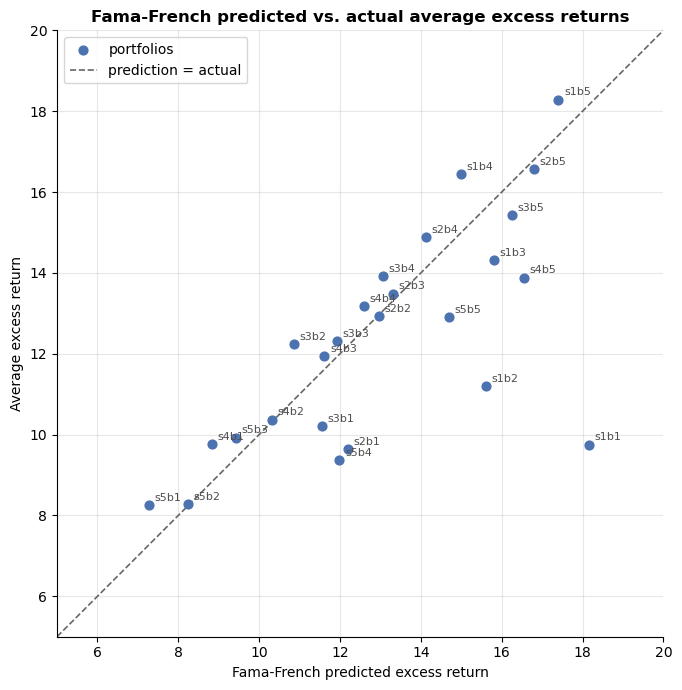

In [41]:
plot_pred_vs_actual(ff3_pred, avg_excess,
                    "Fama-French predicted vs. actual average excess returns",
                    "Fama-French predicted excess return",
                    LIMS)
plt.show()

# Q3